In [1]:
import urllib.request as scrape
from bs4 import BeautifulSoup
import pandas as pd
import time
import math
import os
import string
import logging
import numpy as np

import random
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.autograd import Variable
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
import urllib.request as scrape
import torch
import torch.nn as nn

In [2]:
#print(os.listdir('../input'))
Svenska_namn = pd.read_csv('D:\w اكسل\AABA_2006-01-01_to_2018-01-01.csv') #Data is scraped from https://svenskanamn.alltforforaldrar.se/populart/

In [3]:
def timeSince(since):
    now = time.time()
    s = now - since
    m = math.floor(s / 60)
    s -= m * 60
    return '%dm %ds' % (m, s)


def getTableFromSite(url):
    """
    دالة محدثة بالكامل تتوافق مع التصميم الجديد للموقع السويدي لعام 2026
    """
    headers = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36'
    }
    
    req = scrape.Request(url, headers=headers)
    response = scrape.urlopen(req)
    html_data = response.read()
    response.close()
    
    soup = BeautifulSoup(html_data, 'html.parser')
    
    names = []
    values = []
    
    # 1. البحث عن الأسماء المكتوبة الآن داخل وسوم h2 بالموقع
    h2_elements = soup.find_all('h2')
    
    for h2 in h2_elements:
        name_text = h2.get_text().strip()
        if name_text:
            names.append(name_text)
            
            # 2. البحث عن العدد المتواجد في السطر (الفقرة) التالي مباشرة لعنوان الاسم
            next_p = h2.find_next_sibling('p')
            if next_p and 'personer' in next_p.get_text():
                # استخراج الرقم فقط من الجملة (مثال: "164812 personer" تصبح "164812")
                count_text = next_p.get_text().replace('personer', '').strip()
                values.append(count_text)
            else:
                values.append('0') # قيمة افتراضية في حال عدم العثور على العدد
                
    # إنشاء جدول البيانات بالبنية الصحيحة
    data = pd.DataFrame({'namn': names, 'antal': values})
    return data

def train_validate_test_split(df, train_percent=0.6, validate_percent=0.2, seed=666):
    np.random.seed(seed)
    perm = np.random.permutation(df.index)
    m = len(df.index)
    #print('We found %s lines of data' % m)
    train_end = int(train_percent * m)
    validate_end = int(validate_percent * m) + train_end
    train = df.iloc[perm[:train_end]]
    validate = df.iloc[perm[train_end:validate_end]]
    test = df.iloc[perm[validate_end:]]
    return train, test, validate


def randomChoice(l):
    return l[random.randint(0, len(l) - 1)]


def letter2index(letter):
    return character_list.find(letter)


def indexesFromWord(word):
    return [letter2index(letter) for letter in word]


def tensorFromWord(word):
    indexes = indexesFromWord(word)
    return torch.tensor(indexes, dtype=torch.long).view(-1, 1)


def categoryFromOutput(output):
    top_n, top_i = output.topk(1)
    category_i = top_i[0].item()
    return all_categories[category_i], category_i








def makeBatch_new(batch_size, maxchar, data = None, character_list = None):
    """
    :param batch_size: nr of examples in bach
    :param maxchar: size of longest name in vocabulary
    :return: a padded tensor of size [hh*batch_size*L]
    """
    inds = random.sample(list(data.index), batch_size)
    seqs = list(data['namn'][inds])
    vectorized_seqs = [[character_list.index(tok) for tok in seq] for seq in seqs]
    seq_lengths = [len(x) for x in seqs]
    seq_tensor = Variable(torch.zeros((len(vectorized_seqs), maxchar))).long()

    for idx, (seq, seqlen) in enumerate(zip(vectorized_seqs, seq_lengths)):
        seq_tensor[idx, :seqlen] = torch.LongTensor(seq)

    sorting = sorted([(e, i) for i, e in enumerate(seq_lengths)], reverse=True)
    perm_idx = [x[1] for x in sorting]
    seq_lengths = [x[0] for x in sorting]
    seq_tensor = seq_tensor[perm_idx]
    seq_tensor = seq_tensor.permute(1,0)  #batchFirst

    labels = list(data['gender'][inds])
    label_tensor = torch.LongTensor(batch_size)

    for ii, gender in enumerate(labels):
        if gender == 'flicknamn':
            label_tensor[ii] = 1
        else:
            label_tensor[ii] = 0


    label_tensor = label_tensor[perm_idx]
    return seq_tensor, seq_lengths, label_tensor

In [4]:
class Params():
    def __init__(self):
        self.batch_size = 32
        self.hidden_size = 12
        self.embedding_size = 24
        self.epochs = 50
        self.nr_classes =2
        self.gpu = False
        self.learning_rate = 0.001
        self.train_ratio = 0.82
        self.val_ratio = 0.1
        self.test_ratio = 1-self.val_ratio-self.train_ratio
        self.n_layers = 2
        self.dropout = 0.3


Args = Params()

In [5]:
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.autograd import Variable
from torch.nn import functional as F

class LSTM_classifier(nn.Module):
    def __init__(self, vocab_size, hidden_size, n_layers, dropout, embed_size):
        super().__init__()

        self.input_size = vocab_size
        self.hidden_size = hidden_size
        self.n_layers = n_layers
        self.dropout = dropout
        self.embed_size = embed_size
        self.embedding = nn.Embedding(self.input_size, self.embed_size)
        self.rnn = nn.LSTM(input_size=self.embed_size,
                           hidden_size=hidden_size,
                           dropout=dropout,
                           num_layers=n_layers, bidirectional=True)
        self.hidden2label = nn.Linear(2*hidden_size, 2)
        #self.hidden = self.init_hidden()
        self.softmax = nn.LogSoftmax(dim=1)
        self.dropoutLayer = nn.Dropout()

    def init_hidden(self, batch_size):
        h0 = Variable(torch.zeros(self.n_layers*2, batch_size, self.hidden_size))
        c0 = Variable(torch.zeros(self.n_layers*2, batch_size, self.hidden_size))
        return h0, c0

    def forward(self, inputs, input_lengths):  # inputs: antal i batch x max ord längd
        self.hidden = self.init_hidden(inputs.size(-1)) # -1 if batch_first=False
        embedded = self.embedding(inputs)  # antal i batch * max ord längd * Embedding_dim
        packed = pack_padded_sequence(embedded, input_lengths, batch_first=False)  # packad
        outputs, self.hidden = self.rnn(packed, self.hidden)  #(packed, self.hidden)  #
        output, output_lengths = pad_packed_sequence(outputs, batch_first=False)
        #print(output.size())
        output = torch.transpose(output, 0, 1)
        #print(output.size())
        output = torch.transpose(output, 1, 2)
        #print(output.size())
        output = torch.tanh(output)
        #print(output.size())
        output, indices = F.max_pool1d(output,output.size(2), return_indices=True)
        #print(output.size())
        output = torch.tanh(output)
        output = output.squeeze(2)
        output = self.dropoutLayer(output)
        #print(output.size())
        output = self.hidden2label(output)
        #print(output.size())
        output = self.softmax(output)
        return output, self.hidden

In [6]:
letters = 'abcdefghijklmnopqrstxyz'
max_pages = 3
test_url = 'https://svenskanamn.alltforforaldrar.se/populart/flicknamn/h/page:2'
base_url = 'https://svenskanamn.alltforforaldrar.se/populart/'
genders = ['flicknamn', 'pojknamn']
pages = ['1', '2', '3']

# 1. تصحيح التحقق من المجلد لتجنب توقف الكود (FileNotFoundError)
input_dir = '../input'
file_name = 'AABA_2006-01-01_to_2018-01-01.csv'

if os.path.exists(input_dir) and file_name in os.listdir(input_dir):
    Svenska_namn = pd.read_csv(r'D:\w اكسل\AABA_2006-01-01_to_2018-01-01.csv')
else:
    print("المجلد أو الملف غير موجود محلياً، سيتم البدء في سحب البيانات من الموقع الآن...")
    all_frames = [] # مصفوفة لتجميع جداول البيانات
    for i, letter in enumerate(letters):
        for j, gender in enumerate(genders):
            for k, page in enumerate(pages):
                url = base_url + gender + '/' + letter + '/page:' + page
                try:
                    df = getTableFromSite(url)
                    df['gender'] = gender
                    all_frames.append(df)
                    Svenska_namn = pd.concat(all_frames, ignore_index=True)
                    print(url,'total_rows: ', Svenska_namn.shape[0],)
                except Exception as e:
                    print(f"خطأ أثناء جلب الرابط {url}: {e}")
                time.sleep(1)

    Svenska_namn.to_csv('Svenska namn.csv', index=False)
    

#build a sorted list of possible characters
Svenska_namn['namn'] = Svenska_namn['namn'].str.lower()
lista = list(Svenska_namn['namn'])
charlist = "åäöÅÄÖ -"
for ii in range(len(lista)):
    charlist = charlist + str(lista[ii])

lista = ''.join(set(charlist))
lista = ''.join(sorted(lista))
character_list = sorted(set(charlist))
categories = ['pojknamn', 'flicknamn']
n_letters = len(character_list)
n_categories = len(categories)

#Split the data 
train_data, val_data, test_data = train_validate_test_split(Svenska_namn,seed=333)

model = LSTM_classifier(vocab_size = n_letters, 
                        hidden_size = Args.hidden_size, 
                        n_layers = Args.n_layers, 
                        dropout = Args.dropout,
                        embed_size = Args.embedding_size)

optimizer = torch.optim.Adam(model.parameters())
criterion = nn.CrossEntropyLoss()

def train(input_tensor, input_sizes, target_tensor):
    model.hidden = model.init_hidden(Args.batch_size) 
    model.zero_grad()
    output, hidden = model.forward(input_tensor, input_sizes)
    loss = criterion(output, target_tensor)
    loss.backward()
    optimizer.step()
    return output, loss.item()

المجلد أو الملف غير موجود محلياً، سيتم البدء في سحب البيانات من الموقع الآن...
https://svenskanamn.alltforforaldrar.se/populart/flicknamn/a/page:1 total_rows:  20
https://svenskanamn.alltforforaldrar.se/populart/flicknamn/a/page:2 total_rows:  40
https://svenskanamn.alltforforaldrar.se/populart/flicknamn/a/page:3 total_rows:  60
https://svenskanamn.alltforforaldrar.se/populart/pojknamn/a/page:1 total_rows:  80
https://svenskanamn.alltforforaldrar.se/populart/pojknamn/a/page:2 total_rows:  100
https://svenskanamn.alltforforaldrar.se/populart/pojknamn/a/page:3 total_rows:  120
https://svenskanamn.alltforforaldrar.se/populart/flicknamn/b/page:1 total_rows:  140
https://svenskanamn.alltforforaldrar.se/populart/flicknamn/b/page:2 total_rows:  160
https://svenskanamn.alltforforaldrar.se/populart/flicknamn/b/page:3 total_rows:  180
https://svenskanamn.alltforforaldrar.se/populart/pojknamn/b/page:1 total_rows:  200
https://svenskanamn.alltforforaldrar.se/populart/pojknamn/b/page:2 total_rows: 

In [7]:
#Training
import time


current_loss = 0

all_losses = []
val_acc = []
train_acc = []
predictions = []
labels = []
print_every = int(len(train_data)/Args.batch_size) #every epoch
n_iters  = int(len(train_data)/Args.batch_size*Args.epochs)
plot_every = print_every
start = time.time()


for iter in range(n_iters):
    input_tensor, input_lengths, target_tensor = makeBatch_new(batch_size=Args.batch_size, 
                                                               maxchar= 14, 
                                                               data = train_data, 
                                                               character_list = character_list)
    output, loss = train(input_tensor=input_tensor, 
                         input_sizes=input_lengths, 
                         target_tensor=target_tensor)
    current_loss += loss
    predictions.extend(list(torch.argmax(output, dim=1).numpy()))
    labels.extend(list(target_tensor.numpy()))
    # Print iter number, loss, name and guess
    if (iter) % print_every == 0:
        corrects = 0
        corrects_train = 0
        input_tensor, input_lengths, target_tensor = makeBatch_new(batch_size=len(val_data), 
                                                                   maxchar= 14, 
                                                                   data =val_data, 
                                                                   character_list = character_list)
        
        output, hidden = model(inputs = input_tensor, input_lengths = input_lengths)
        preds = torch.argmax(output, dim=1)
        for i in range(len(preds)):
            if preds[i] == target_tensor[i]:
                corrects += 1
        
        for i in range(len(labels)):
            if labels[i] == predictions[i]:
                corrects_train +=1
        
        
        accuracy = corrects/len(preds)
        train_accuracy = corrects_train/len(labels)
        
        val_acc.append(accuracy)
        train_acc.append(train_accuracy)
        labels = []
        predictions =[]
        print('Val acc after {} epochs is: {} - train acc: {} - time elapsed: {} - avg train loss: {}'.format(int(iter/print_every+1), round(accuracy, 2),round(train_accuracy,2), timeSince(start), round(loss, 2)))

        
    if iter % plot_every == 0:
        all_losses.append(current_loss / plot_every)
        current_loss = 0 

Val acc after 1 epochs is: 0.45 - train acc: 0.41 - time elapsed: 0m 0s - avg train loss: 0.7
Val acc after 2 epochs is: 0.48 - train acc: 0.51 - time elapsed: 0m 1s - avg train loss: 0.7
Val acc after 3 epochs is: 0.53 - train acc: 0.57 - time elapsed: 0m 2s - avg train loss: 0.68
Val acc after 4 epochs is: 0.58 - train acc: 0.59 - time elapsed: 0m 4s - avg train loss: 0.67
Val acc after 5 epochs is: 0.66 - train acc: 0.66 - time elapsed: 0m 5s - avg train loss: 0.57
Val acc after 6 epochs is: 0.74 - train acc: 0.73 - time elapsed: 0m 6s - avg train loss: 0.5
Val acc after 7 epochs is: 0.76 - train acc: 0.76 - time elapsed: 0m 7s - avg train loss: 0.6
Val acc after 8 epochs is: 0.78 - train acc: 0.79 - time elapsed: 0m 8s - avg train loss: 0.48
Val acc after 9 epochs is: 0.77 - train acc: 0.8 - time elapsed: 0m 10s - avg train loss: 0.44
Val acc after 10 epochs is: 0.8 - train acc: 0.8 - time elapsed: 0m 11s - avg train loss: 0.28
Val acc after 11 epochs is: 0.8 - train acc: 0.82 - ti

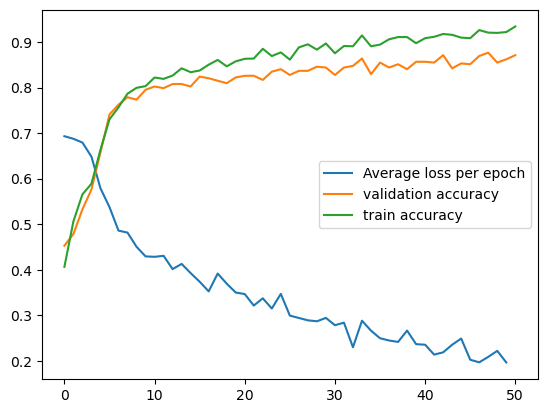

In [8]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
%matplotlib inline

plt.figure()
plt.plot(all_losses[1:])
plt.plot(val_acc[:])
plt.plot(train_acc[:])
plt.legend(['Average loss per epoch','validation accuracy','train accuracy'])